<a id="top"></a>
# GridGuard AI: Contingency Screening on a Synthetic IEEE 118-Bus Benchmark with PySpark

### A Leakage-Aware Evaluation with PySpark

**Sileshi T. Hirpa**  
Arizona State University  
Data Science, Business Analytics Track  
October 2026

Portfolio Research and Engineering Report

A scenario-grouped study of machine-learning ranking for modeled thermal violations on a synthetic IEEE 118-bus benchmark.

**Data note:** Canonical datasets are private and are not distributed. This report renders sanitized aggregate evidence. Executing its cells does not repeat model training or final-test evaluation.

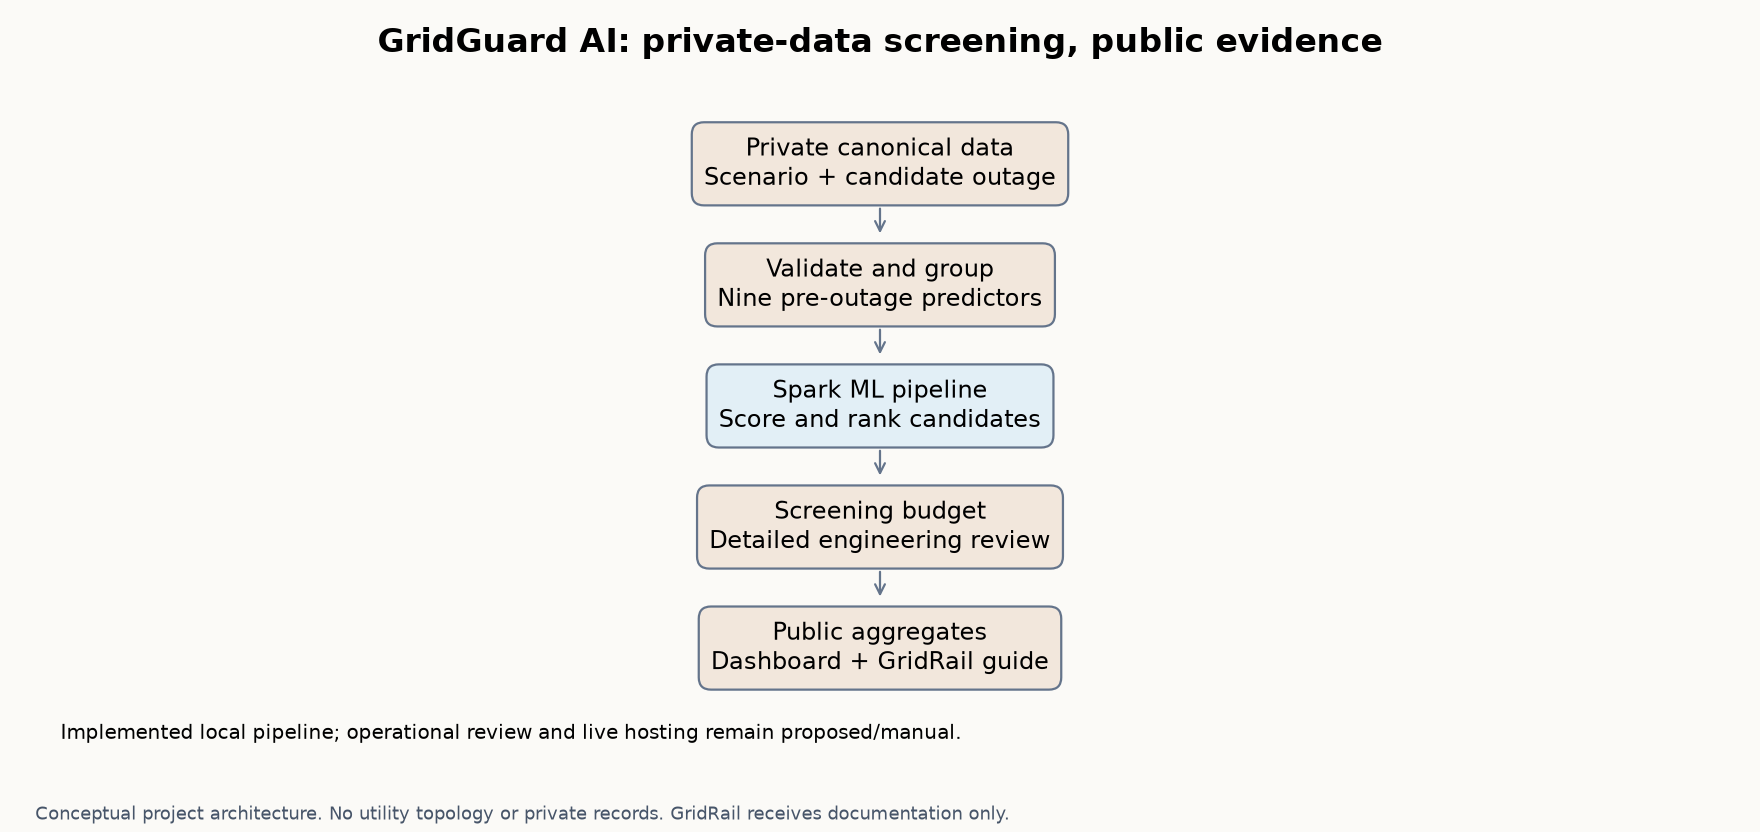

**Insight.** Private inputs feed validation and scoring. Public surfaces receive aggregates and documentation.  
**Operational implication.** Keep the analysis boundary separate from any future engineering workflow.  
**Caution.** This diagram represents project design, not a deployed utility system.

**Reproducibility scope:** The original executable physics generator was not recovered. Full canonical-data regeneration is not claimed. ML reproduction requires authorized external canonical data. Tests and this aggregate report run without private datasets. The report originated from CIS 415 work and adds independent portfolio engineering. Restricted course materials and instructor code are not redistributed. Affiliation is descriptive, not university endorsement.

**Live research dashboard:** [gridguard-ai.pages.dev](https://gridguard-ai.pages.dev)

The dashboard provides an interactive view of the same sanitized validation evidence summarized in this report. It does not expose private canonical data or perform live grid predictions. It is a presentation surface, not additional scientific evidence. GridRail remains a non-live project-guide placeholder and provides no live AI-generated answers.


## Contents

1. [Executive Summary](#executive-summary)
2. [Problem](#research-question)
3. [Related Work](#literature-review)
4. [Data: Provenance, Integrity and EDA](#data-provenance)
5. [Experimental Design](#experimental-design)
6. [Modeling and Tuning Check](#modeling)
7. [Validation Results](#model-evaluation)
8. [Fresh 1M Dataproc Results](#fresh-dataproc)
9. [Operational Interpretation and Batch Scoring](#batch-scoring)
10. [Limitations](#limitations)
11. [Reproducibility](#reproducibility)
12. [Conclusion](#conclusions)
13. [References and Appendices](#references)


In [1]:
from pathlib import Path
import sys, json, os
ROOT = Path.cwd()
if not (ROOT / "src/gridguard").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src/gridguard").is_dir(), "Run from the repository or notebooks directory"
sys.path.insert(0, str(ROOT / "src"))
from gridguard.reporting import load_json, table, metric_rows, screening_rows, audit_aggregates, figures, references
from gridguard.features import FEATURES, METADATA, TARGET
from IPython.display import Markdown, display, Image
print("Report mode: saved aggregate evidence. No training or test scoring.")
audit_aggregates(ROOT)
print("Report checks passed: counts and rates agree")
figure_manifest = figures(ROOT)
def show_figure(name):
    display(Image(filename=str(ROOT / "results/figures" / (name + ".png"))))
def show_table(records, columns=None):
    display(Markdown(table(records, columns)))

Report mode: saved aggregate evidence. No training or test scoring.


Report checks passed: counts and rates agree


<a id="executive-summary"></a>
## 1. Executive Summary


### Objective
Can ranking retain modeled violations at a fixed review budget on a synthetic IEEE 118-bus DC benchmark?

### Method
Use scenario-grouped validation and compare GBT with the strongest tested simple baseline, pre-outage loading. The local 1M audit covers 865 validation scenarios and 153,105 cases. Nine raw features were ranked descending, without sign search, and loading times sensitivity was also tested.

### Evidence
At 20% review, loading captured 78.78% and GBT 95.07%, a gain of 16.29 percentage points with a 95% paired scenario-bootstrap interval of +15.75 to +16.72 points. At 10%, capture was 54.33% versus 78.92%, a +24.59-point gain with interval +23.23 to +25.96. The bootstrap used 1,000 scenario resamples with the model fixed. Fresh Dataproc evidence is reported separately in Section 8.

### Insight
The local GBT ranking retained more modeled violations at the same review budget than the strongest tested simple baseline.

### Decision or implication
The written policy freezes pooled top-20% review as primary, within-scenario top-20% recall as secondary, and 10% as the tighter-budget analysis. A future final-test run requires separate written authorization.

### Limitation
The held-out 1M test remains unevaluated. Intervals do not correct selection optimism or calibration overlap. The original generator is missing. These synthetic DC results do not establish utility performance.


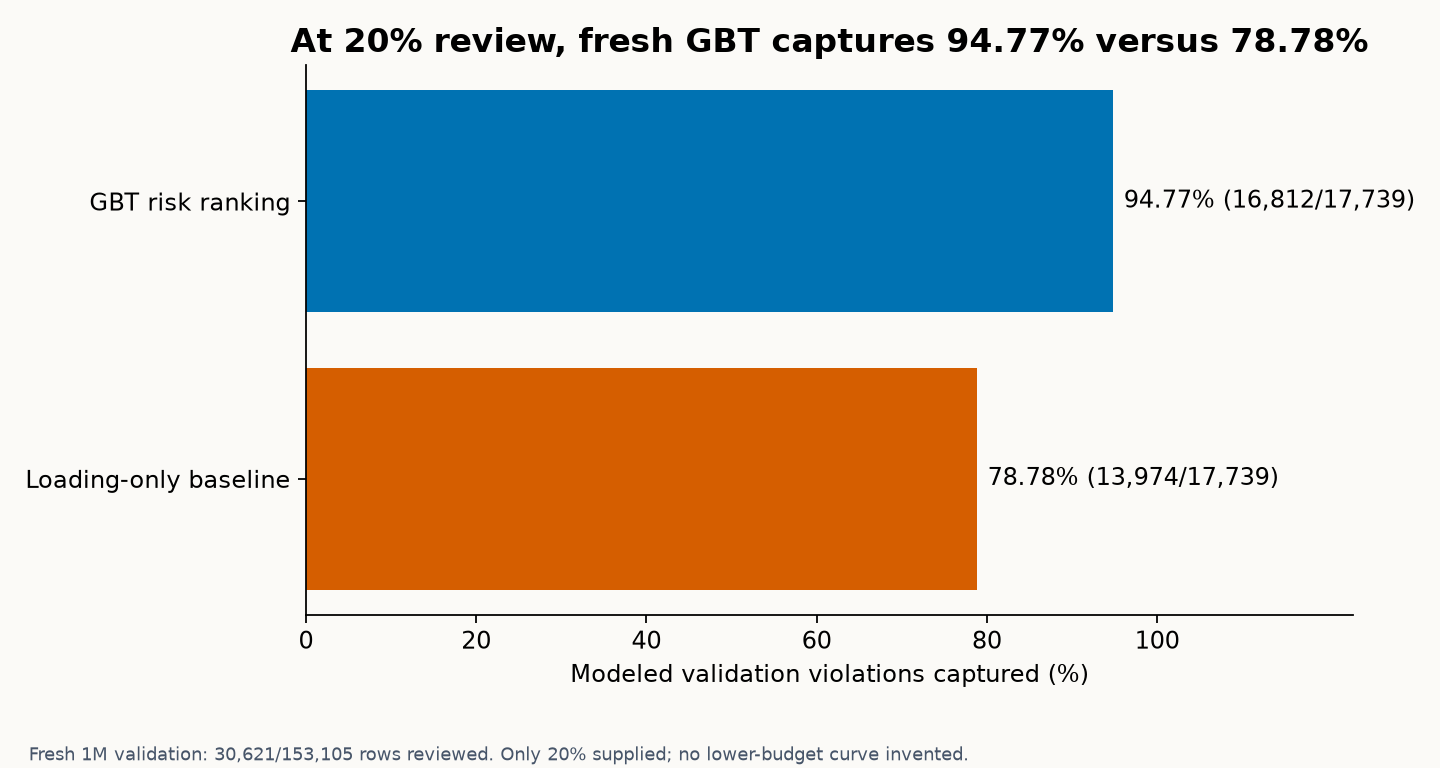

In [2]:
show_figure("dataproc_screening_20pct")

**Insight.** Fresh 1M Dataproc validation capture is 94.77% versus 78.78% loading-only at 20% review.

**Operational implication.** 80% of candidate cases remain outside the review set. 927 modeled positives are still missed.

**Caution.** The four-budget 50K development analysis remains separately labeled later in the report.


[Back to Top](#scrollTo=gridguard-cover)


<a id="research-question"></a>
## 2. Problem



Contingency analysis checks how a power network responds to a candidate outage. Screening ranks candidates for detailed study. The intended reader is an engineer planning a study batch, before any dispatch or operating decision. A missed positive is a modeled violating outage that does not reach detailed review.

### Motivation

DC power flow and LODF calculations can be inexpensive. This study does not show that learning is faster or more accurate than computing its DC labels directly. The synthetic DC/LODF labels form a known-truth testbed for checking a ranking and evaluation workflow before using more expensive targets such as AC, N-k or dynamic studies. Exact physical dataset generation remains unverified because the original generator is missing.

### Problem Statement

The unit is one operating scenario paired with one candidate line outage. Nine declared pre-outage features rank outages according to modeled post-outage thermal violations on any remaining line. The current published ranking pools validation cases across scenarios. New evaluation code also measures recall within each scenario at 10% and 20% review. The completed local validation audit reports these results. A loading-times-sensitivity heuristic and the best raw single-feature ranking strengthen the loading-only comparison. They are not substitutes for classical full-network performance indices.



[Back to Top](#scrollTo=gridguard-cover)


<a id="literature-review"></a>
## 3. Related Work


The literature explains contingency analysis, DC approximations, imbalanced retrieval, grouped validation and distributed learning. The cited sources provide context rather than directly comparable baselines. The study combines established methods and does not propose new physical or statistical theory.

Sixteen verified sources and their claim mappings are retained. Literature expansion is outside this implementation stage. The review below distinguishes DC thermal screening from AC voltage, reactive-power and stability assessment.


### Power-system contingency analysis

N-1 analysis examines system response after a single element outage. Planning assessments include performance requirements beyond thermal overload. GridGuard ranks modeled line-outage cases for review. It does not certify compliance or operational security ([North American Electric Reliability Corporation [NERC], n.d.](https://www.nerc.com/globalassets/standards/reliability-standards/tpl/tpl-001-5.1.pdf)).

### DC power flow and LODF

The DC formulation simplifies steady-state active-power flows and does not resolve full AC voltage/reactive behavior ([Zimmerman et al., 2011](https://doi.org/10.1109/TPWRS.2010.2051168)). Line-outage distribution factors (LODFs) approximate branch-flow changes in a DC network. MATPOWER documents bridge masking for outages that island a network ([MATPOWER Developers, n.d.-b](https://matpower.org/documentation/ref-manual/legacy/functions/makeLODF.html)). Project reports describe DC/LODF labels, but the missing generator prevents independent verification of their exact construction.

### Benchmark-network context

MATPOWER case118 documents conversion from an IEEE Common Data Format case in the University of Washington archive ([MATPOWER Developers, n.d.-a](https://matpower.org/docs/ref/matpower6.0/case118.html)). This supports benchmark attribution, not a claim that the canonical CSV uses an unmodified case or represents a current utility. Synthetic calibrated thermal ratings require separate validation.

### ML-based security assessment and screening

Learned security classifiers have prior art on other networks and security targets ([Hidalgo-Arteaga et al., 2019](https://doi.org/10.1109/PTC.2019.8810906)). Deliberate sampling of operating regions and security boundaries is central to dataset generation ([Thams et al., 2020](https://doi.org/10.1109/TPWRS.2018.2890769)). GridGuard instead evaluates tabular LR, RF and GBT on a fixed thermal-label benchmark. The studies are context, not directly comparable performance baselines or a novelty claim.

### Imbalanced classification and PR-AUC

Precision-recall analysis emphasizes positive-class retrieval under imbalance ([Saito & Rehmsmeier, 2015](https://doi.org/10.1371/journal.pone.0118432)). GridGuard reports PR-AUC alongside recall, precision, F1 and explicit false negatives. Area under the Spark PR curve is not automatically identical to average precision in other libraries. Validation prevalence is the relevant random-ranking reference, and deployment costs cannot be inferred from F1 alone.

### Leakage-aware grouped validation

Learn-predict separation excludes information unavailable at decision time ([Kaufman et al., 2012](https://doi.org/10.1145/2382577.2382579)). Group-based validation addresses dependence among observations sharing an underlying unit ([Roberts et al., 2017](https://doi.org/10.1111/ecog.02881)). All outages from one operating scenario stay in one partition. Grouping does not remove synthetic sampling bias, shared topology dependence or historical test-set exposure.

### Distributed Spark implementation

RDD lineage and partitioned processing support iterative distributed computation ([Zaharia et al., 2012](https://www.usenix.org/conference/nsdi12/technical-sessions/presentation/zaharia)). Spark pipelines sequence estimators and transformers ([The Apache Software Foundation, n.d.-a](https://spark.apache.org/docs/3.5.8/ml-pipeline.html)). toPandas collects results into driver memory ([The Apache Software Foundation, n.d.-b](https://spark.apache.org/docs/3.5.8/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.toPandas.html)). The current code aggregates in Spark. Documentation version 3.5.8 explains concepts. Reproduced runtime is 4.0.1. Historical refactoring evidence does not establish a controlled speedup.

### Reproducibility and responsible reporting

Dataset documentation should expose composition and intended use ([Gebru et al., 2021](https://doi.org/10.1145/3458723)), while model cards document performance and limitations ([Mitchell et al., 2019](https://doi.org/10.1145/3287560.3287596)). GridGuard distinguishes historical, reproduced, enhanced and proposed evidence, with private input configuration and aggregate-only public artifacts.

### Positioning of GridGuard AI

Random forests aggregate randomized trees ([Breiman, 2001](https://doi.org/10.1023/A:1010933404324)). Gradient boosting iteratively optimizes an additive predictor ([Friedman, 2001](https://doi.org/10.1214/aos/1013203451)). LR is a conventional linear-logit reference, with implementation parameters disclosed. GBT performs best among the fixed evaluated baselines here. This observational result does not explain causally why it wins or establish superiority on unseen grids.


[Back to Top](#scrollTo=gridguard-cover)


<a id="data-provenance"></a>
## 4. Data: Provenance, Integrity and EDA


Canonical files are identified by SHA-256 without publishing their records. The 50K hash is `0647a744810f26691d2f46ee176a2d167c1beb1ce88a076be69a69b445226ec9`. The 1M hash is `66d3e763848cb7fa07867dd83587b1125b53366df6dd1af0dd54b7739e0c8aa6`.

Historical documentation describes DC/LODF simulation with calibrated ratings. The missing executable generator prevents independent physical regeneration and exact feature-construction verification. MATPOWER benchmark lineage does not prove the exact canonical CSV generation process. Authorized inputs remain external, as described in [data access](../docs/PRIVATE_DATA_ACCESS.md).


In [3]:
show_table([dict(dataset=s, **load_json(ROOT, f"results/{s}/validation.json")) for s in ["small", "big"]], ["dataset", "rows", "positive_count", "prevalence", "unique_scenarios", "versions"])

| dataset | rows | positive_count | prevalence | unique_scenarios | versions |
|---|---|---|---|---|---|
| small | 50000 | 5732 | 0.11464 | 5650 | ['ieee118_dc_lodf_v1'] |
| big | 1000000 | 117193 | 0.117193 | 5650 | ['ieee118_dc_lodf_v1'] |


Read-only checks cover finite predictors, binary labels, version, unique scenario-outage pairs, missingness and scenario counts. The 50K integrity profile has 15 columns, no missing cells and no duplicate pairs. The range table describes this benchmark rather than valid utility operating limits.

Both datasets cover the same 5,650 scenarios. Increasing to 1M rows adds outage coverage, not independent states. The local validation EDA below describes feature-target relationships and scenario structure.


### Validation EDA and decisions

| Validation aggregate | Measured evidence | Decision or caution |
|---|---|---|
| Scenario structure | 865 scenarios, exactly 177 candidate outages each. Positive-count quartiles 13, 17, 25. Zero-positive scenarios: 0 | Keep operating scenarios together in splitting and report scenario recall |
| Prevalence | 17,739 positives in 153,105 rows, 11.59% | Use PR-AUC and prevalence-aware capture ceilings |
| Pre-outage loading | Class means: 28.2 negative, 63.5 positive. Descending single-feature PR-AUC 0.639 | Strongest tested simple baseline |
| Thermal rating | Class means: 62.8 negative, 140.2 positive. PR-AUC 0.617 | Reinforces rating-calibration overlap caution, without proving causation |
| Line outage sensitivity | Class means: 0.823 negative, 0.821 positive. PR-AUC 0.112 | Weak marginal descending ranking, no sign search performed |

These are local validation EDA aggregates, not final-test evidence. Rating calibration may overlap the modeled scenarios.


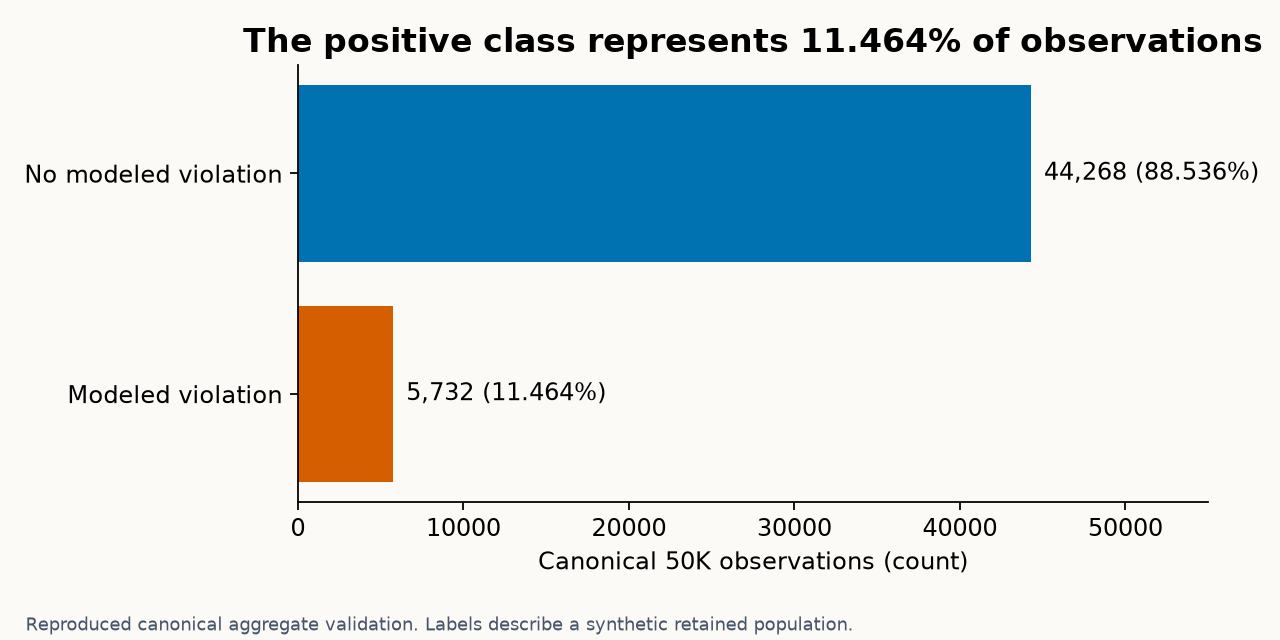

In [4]:
show_figure("class_balance")

88.536% of canonical rows are negative.

A majority-negative classifier would have high accuracy but miss every positive. Inspect recall and PR-AUC.

PR baseline depends on evaluation prevalence, which differs slightly by partition.


In [5]:
profile = load_json(ROOT, "results/small/report_integrity.json")
show_table([dict(feature=k, minimum=v[0], maximum=v[1], type="numeric") for k,v in profile["predictor_ranges"].items()])

| feature | minimum | maximum | type |
|---|---|---|---|
| Total_Demand | 2713.34 | 5164.7 | numeric |
| Renewable_Generation_Pct | 5 | 47.7005 | numeric |
| Hour_of_Day | 0 | 23 | numeric |
| Pre_Outage_Line_Loading | 0.001711 | 99.2338 | numeric |
| Line_Thermal_Rating | 55 | 441.821 | numeric |
| Edge_Betweenness | 0.000579 | 0.257444 | numeric |
| Degree_From_Bus | 2 | 9 | numeric |
| Degree_To_Bus | 2 | 9 | numeric |
| Line_Outage_Sensitivity | 0.265902 | 1 | numeric |


## Evaluation limits

The 50K and 1M datasets share the same 5,650 operating scenarios. The 1M dataset adds denser outage coverage rather than independent operating states. Ratings were reportedly calibrated on 5,000 scenarios. Their overlap with modeled scenarios is unknown, so calibration may carry information from validation or test flows. Existing published review rankings pool cases across scenarios and do not enforce equal review capacity within each state. The completed local audit reports heuristic and within-scenario comparisons.

Feature-target summaries, zero-positive shares and descending single-feature rankings are recorded in the completed validation audit.


[Back to Top](#scrollTo=gridguard-cover)


<a id="experimental-design"></a>
## 5. Experimental Design


VectorAssembler uses the explicit nine-feature list and rejects invalid values. Scenario and outage IDs, other metadata and the target are excluded. Hour is numeric rather than cyclic, and the endpoint degree features are counts. Exact sensitivity construction and pre-contingency availability are not independently established.


In [6]:
show_table([{"role":"predictor", "fields":", ".join(FEATURES)}, {"role":"metadata excluded", "fields":", ".join(METADATA)}, {"role":"target excluded", "fields":TARGET}])

| role | fields |
|---|---|
| predictor | Total_Demand, Renewable_Generation_Pct, Hour_of_Day, Pre_Outage_Line_Loading, Line_Thermal_Rating, Edge_Betweenness, Degree_From_Bus, Degree_To_Bus, Line_Outage_Sensitivity |
| metadata excluded | scenario_id, outage_line_id, islanding_flag, random_seed, dataset_version |
| target excluded | Post_Outage_Violation |


Distinct scenario IDs are sorted into one partition before the 70/30 and 50/50 Spark split with seed 4152026. Joined partitions must have pairwise disjoint scenario sets. This prevents related outage rows crossing partitions, but does not remove shared-topology dependence or possible rating-calibration overlap.


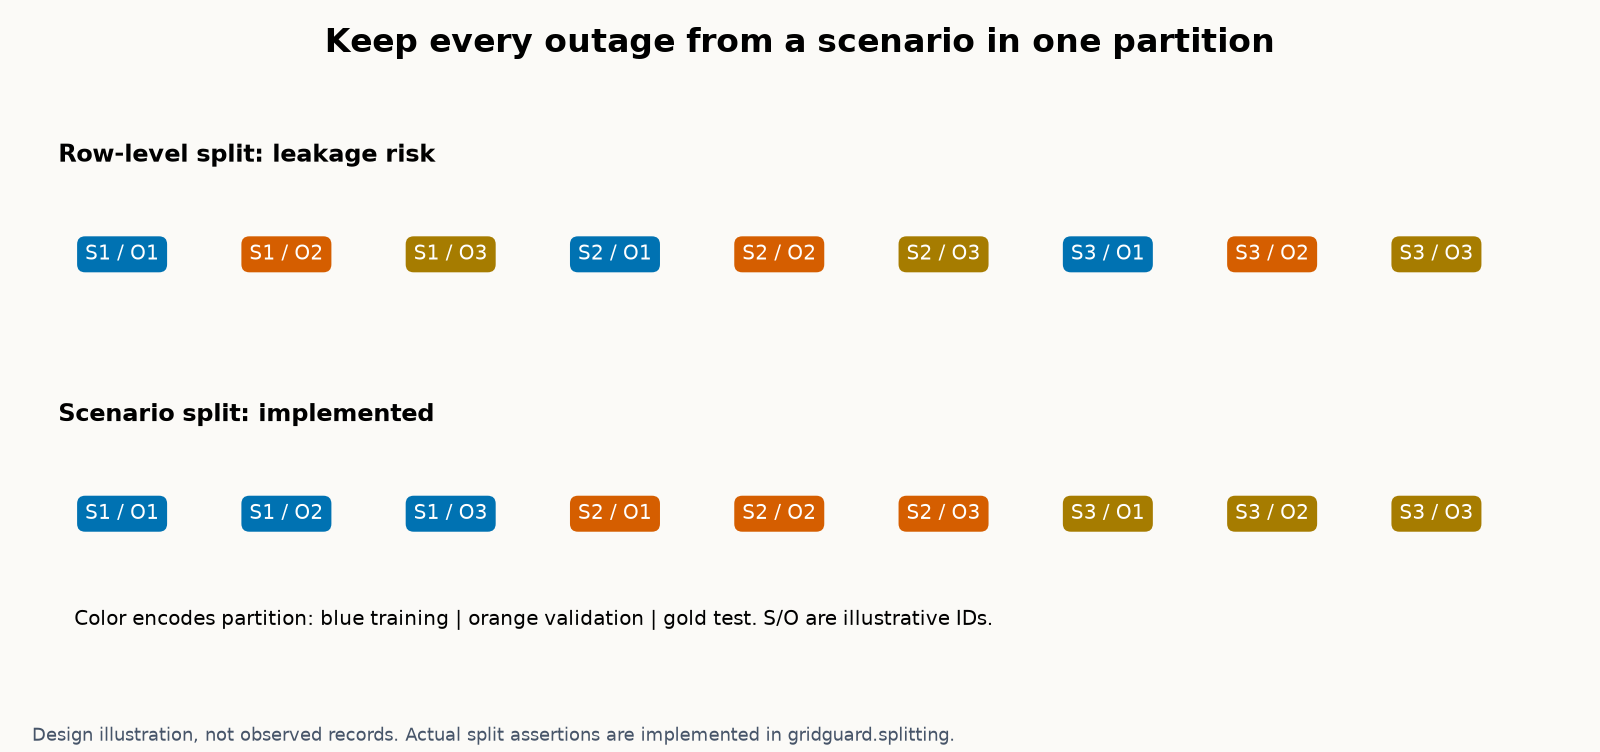

In [7]:
show_figure("grouped_split")

Random row splitting can distribute outages from the same scenario across partitions.

Split the scenario table before joining outage rows.

Illustrative IDs only. No raw scenario rows shown. Grouped evaluation is not evidence of transfer to a new grid.


In [8]:
show_table([dict(partition=k, **v) for k,v in load_json(ROOT,"results/small/split_summary.json").items()])

| partition | rows | positive_count | unique_scenarios | prevalence |
|---|---|---|---|---|
| train | 34827 | 4014 | 3934 | 0.115255 |
| validation | 7651 | 872 | 865 | 0.113972 |
| test | 7522 | 846 | 851 | 0.11247 |


[Back to Top](#scrollTo=gridguard-cover)


<a id="modeling"></a>
## 6. Modeling and Tuning Check


Logistic regression, RF and GBT use the same nine predictors and scenario partitions. They are near-default capacity baselines rather than equally tuned models. RF has 20 trees with maximum depth 5. GBT has 20 iterations with maximum depth 5. Effective fitted settings are retained in the appendix.

The earlier 50K comparison is development evidence. The fresh 1M comparison appears separately below. The completed audit compares loading times sensitivity and validation-selected descending single-feature rankings.


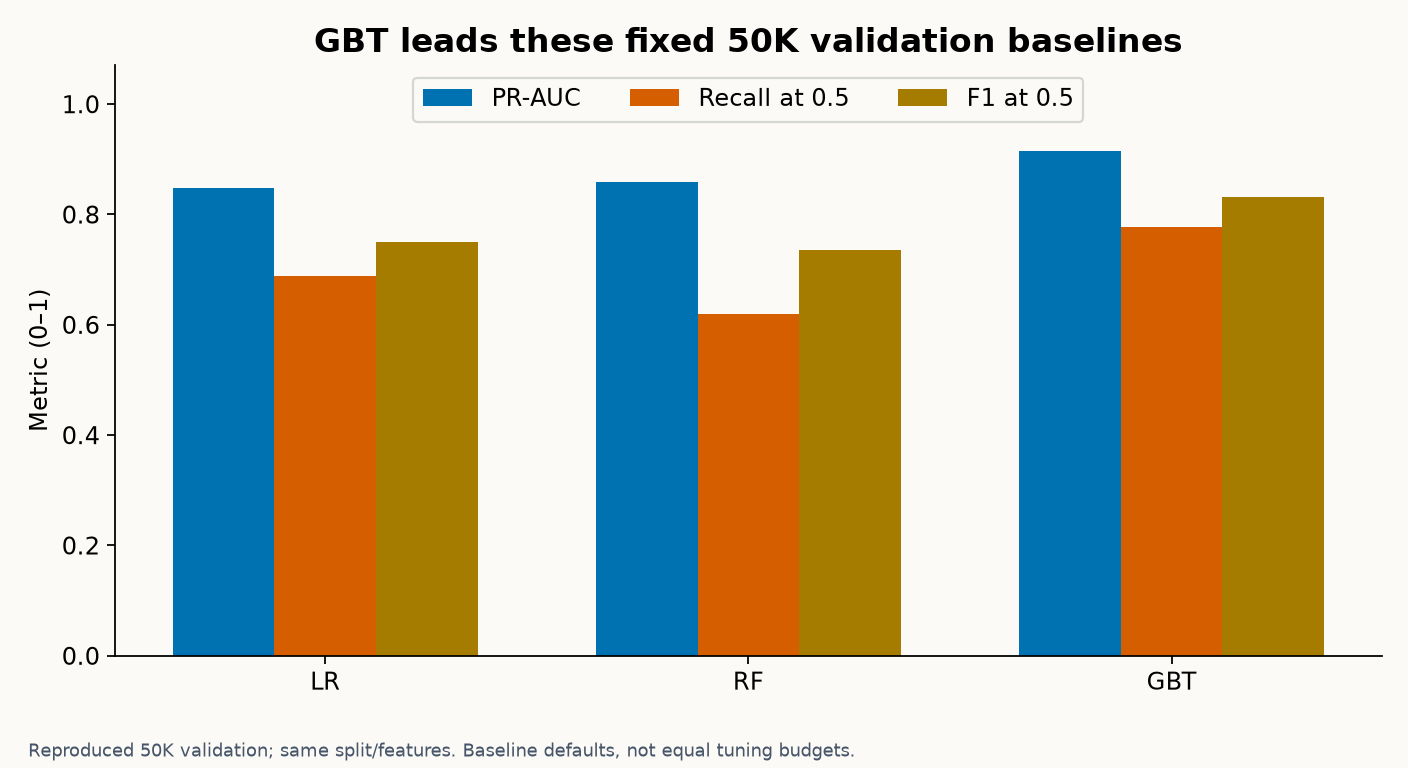

In [9]:
show_figure("model_comparison")

GBT leads PR-AUC, recall and F1 among fixed 50K baselines.

Retain all baseline results and effective parameter maps for review.

Recall/F1 shown at threshold 0.5, before the selected 0.4 operating threshold.


The earlier GBT tuning check compared depths 3 and 5, with 20 iterations, across three scenario-hash folds within training data only. Mean PR-AUC selected the same baseline configuration. This two-configuration check does not establish a tuning gain or a matched RF/GBT tuning-budget comparison.


In [10]:
tuning=load_json(ROOT,"results/small/tuning.json")
show_table(tuning["records"], ["parameters","fold_scores","mean_PR_AUC"])

| parameters | fold_scores | mean_PR_AUC |
|---|---|---|
| {'maxDepth': 3, 'maxIter': 20} | [0.863576590036629, 0.8669378755519529, 0.8753096277994494] | 0.868608 |
| {'maxDepth': 5, 'maxIter': 20} | [0.9083748432407278, 0.9193545928327101, 0.9176534911698772] | 0.915128 |


[Back to Top](#scrollTo=gridguard-cover)


<a id="model-evaluation"></a>
## 7. Validation Results


### Local 1M validation gains

On the local 1M validation split, GBT increased modeled-violation capture at a 20% review budget from 78.8% for the strongest tested simple baseline to 95.1%, a gain of 16.3 percentage points. At 10% review, capture increased from 54.3% to 78.9%, a gain of 24.6 points. Mean per-scenario recall at a 20% budget increased from 79.4% to 93.8%.

These are validation results on a synthetic IEEE 118-bus DC benchmark, not real-grid operational benefits. Loading was the strongest of the tested descending single-feature rankings and loading times sensitivity, selected on these validation rows. Comparisons are descriptive and subject to selection optimism. Capture and scenario-recall uncertainty is reported below.

Here, pp means percentage points. PR-AUC gains use the original 0 to 1 scale.

| Decision metric | Loading baseline | GBT | Improvement |
|---|---:|---:|---:|
| PR-AUC | 0.6390 | 0.9247 | +0.2857 |
| Capture at 10% review | 54.33% | 78.92% | +24.59 pp |
| Capture at 20% review | 78.78% | 95.07% | +16.29 pp |
| Mean per-scenario recall at 10% | 54.16% | 80.27% | +26.10 pp |
| Mean per-scenario recall at 20% | 79.39% | 93.80% | +14.41 pp |
| Scenarios with at least one miss at 20% | 92.72% | 44.05% | -48.67 pp |

Pooled capture ranks all 153,105 validation cases together. Per-scenario recall ranks outages within each of the 865 positive validation scenarios and then averages their recalls. These are different review policies. At 20%, 44.05% of scenarios still have at least one miss, versus 92.72% for loading, a reduction of 48.67 percentage points. Pooled GBT still misses 875 modeled violations. At 10%, scenario misses fall from 99.42% to 70.40%, a reduction of 29.02 points. At that budget, GBT reaches 91.44% of the nominal pooled ceiling versus 62.95%, a gain of 28.49 points.

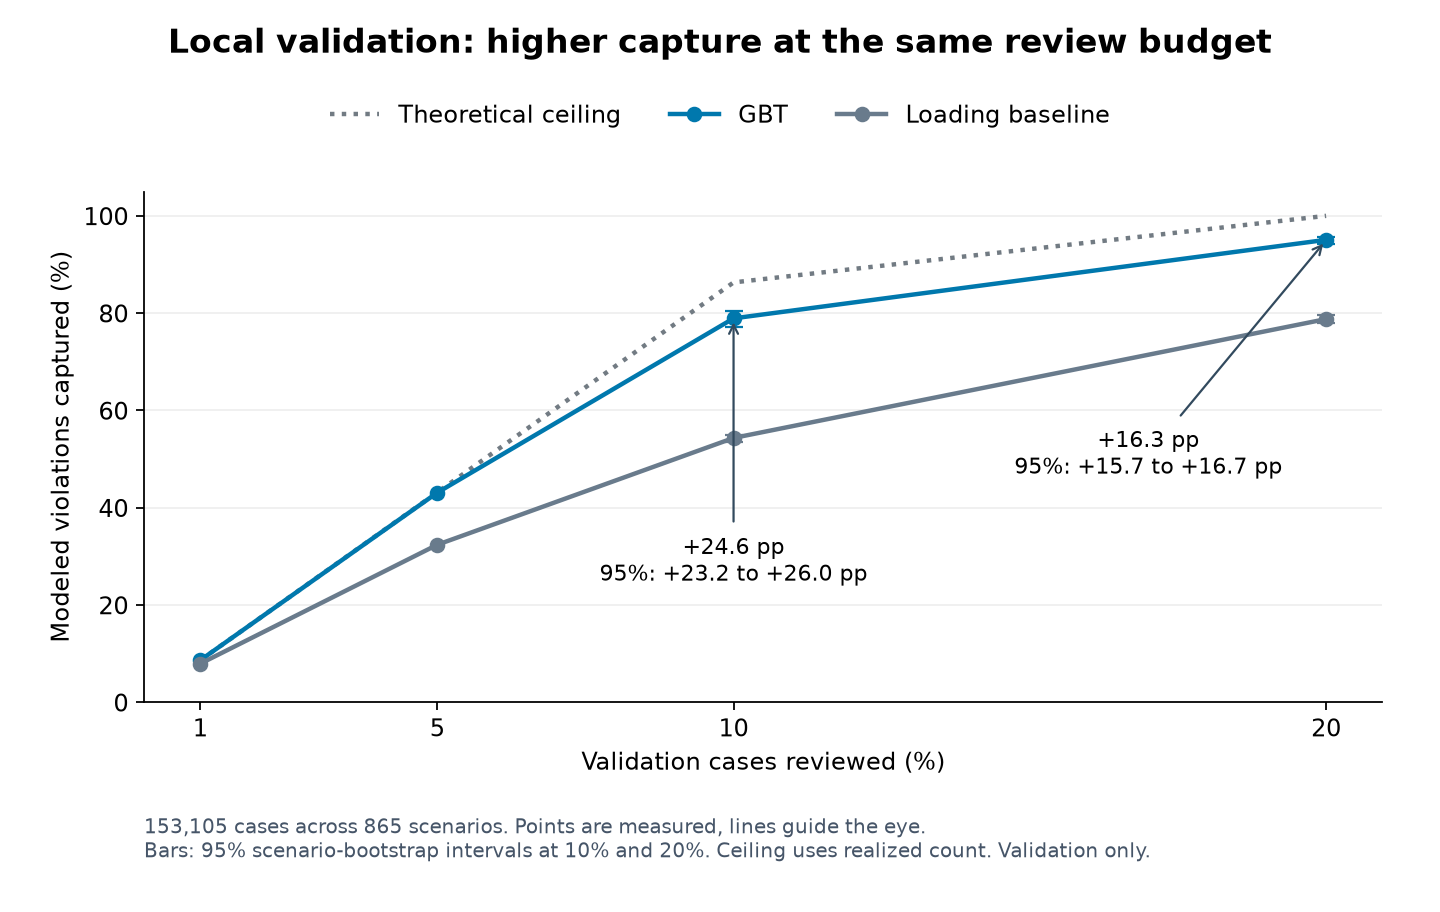

**Insight.** GBT captures more modeled violations at fixed review budgets.

**Operational implication.** The measured benefit is prioritization within this benchmark.

**Caution.** Misses remain and validation comparisons do not certify safety.


### Local validation uncertainty

On 865 validation operating scenarios from the synthetic IEEE 118-bus DC benchmark, GBT increased modeled-violation capture at 20% review from 78.8% to 95.1% versus the strongest tested simple baseline. The gain was 16.3 percentage points. Across 1,000 paired scenario-cluster bootstrap resamples, its 95% percentile interval was 15.75 to 16.72 percentage points.

Here, pp means percentage points. The baseline is pre-outage line loading.

| Decision metric | Loading baseline | GBT | Gain | 95% bootstrap interval for gain |
|---|---:|---:|---:|---:|
| Capture at 10% review | 54.33% | 78.92% | +24.59 pp | +23.23 to +25.96 pp |
| Capture at 20% review | 78.78% | 95.07% | +16.29 pp | +15.75 to +16.72 pp |
| Mean per-scenario recall at 20% | 79.39% | 93.80% | +14.41 pp | +13.85 to +14.97 pp |

At 10% review, the gain was 24.59 percentage points, with a 95% interval of 23.23 to 25.96 points. At 20%, GBT capture had a 95% interval of 94.29% to 95.64%, compared with 78.03% to 79.53% for loading. The bootstrap interval for each reported gain remained entirely above zero within the resampled validation scenarios.

PR-AUC remains 0.9247 for GBT versus 0.6390 for loading, a gain of 0.2857. PR-AUC uncertainty was not reported because the bounded Python bootstrap implementation was not shown to reproduce Spark's areaUnderPR definition exactly.

**Limitation. Intervals do not correct selection optimism or calibration overlap.** The model and validation-selected baseline were fixed. These intervals describe validation ranking on this synthetic benchmark, not real-grid benefits. The held-out 1M test remains unevaluated.

**RF reproducibility.** The fresh Dataproc RF PR-AUC falls within the range observed across 15 local seed-and-partition experiments. This is consistent with Random Forest stochastic variability, but the experiment does not isolate partition count as the unique cause. Fixed-threshold precision was not reproduced by the sensitivity study. The original local precision (0.941) and fresh Dataproc precision (0.878) both fall outside the 15-run local range of approximately 0.890 to 0.937. The RF sensitivity study repartitioned and sorted the training input differently from the original local pipeline, so it samples a neighboring layout family rather than reproducing the original reference run exactly. Local PR-AUC ranged from 0.8612 to 0.8777. Historical 1M results with a different split remain context rather than the direct reproduction target.

### Threshold selection (earlier 50K experiment)

#### Objective
Which threshold defines the saved operating point?

#### Method
Search validation thresholds 0.05,0.1,0.2,…,0.9 and select maximum F1. Freeze model/data/config/features before final test.

#### Evidence
Threshold 0.4 has validation F1=0.831754, recall=0.805046 and 10.6653% flagged.

#### Insight
Max-F1 selection balances errors under an implicit metric preference, not power-system risk cost.

#### Decision or implication
Treat 0.4 as a benchmark operating point pending a domain-specified false-negative cost.

#### Limitation
Threshold chosen on the same validation population, no confidence interval or calibrated risk guarantee. Fine differences in F1 may not generalize.


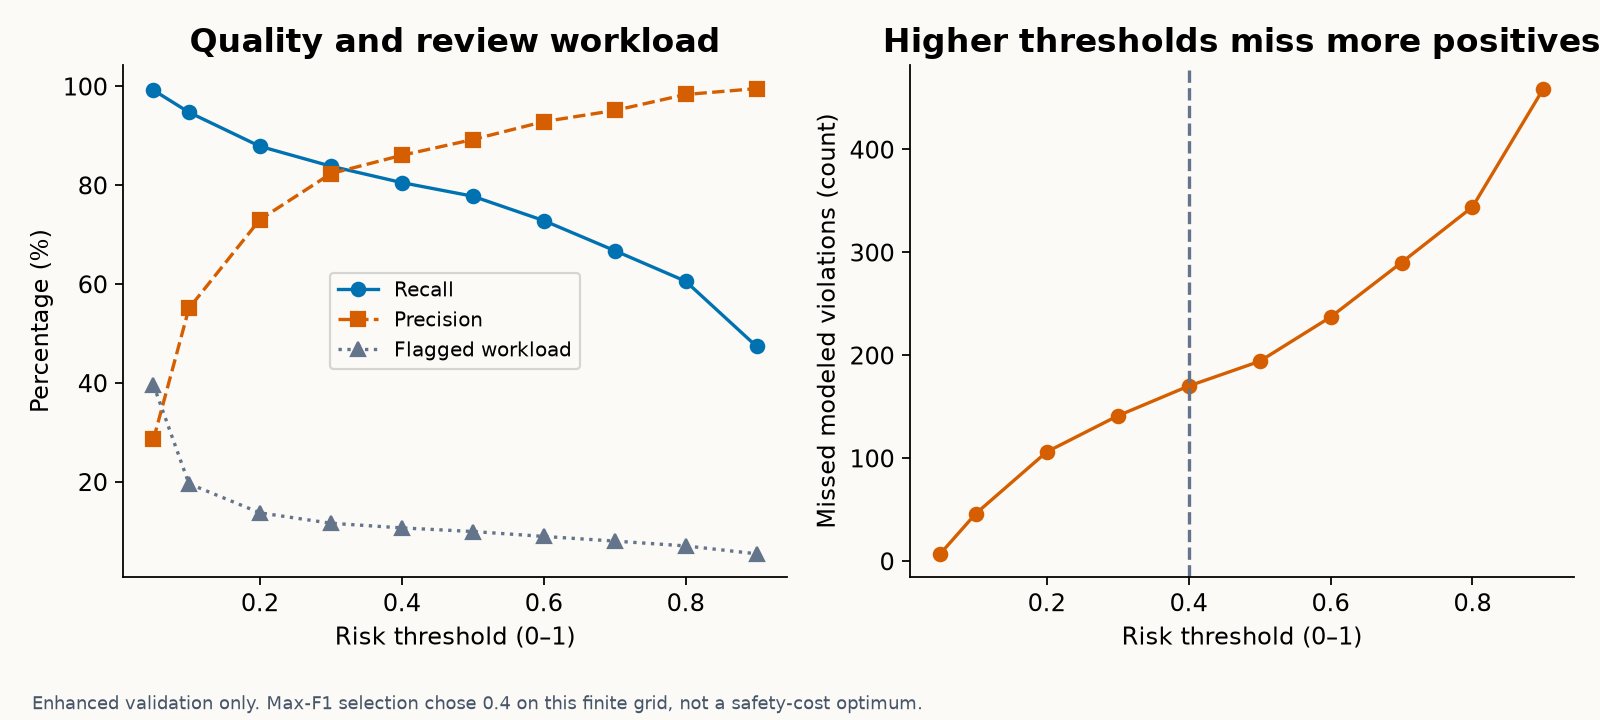

In [11]:
show_figure("threshold_tradeoff")

**Insight.** Lower thresholds recover more positives at greater flagged workload.

**Operational implication.** Set the acceptable miss rate and review capacity with engineers.

**Caution.** F1 optimization is not an operational safety criterion.


### Evaluation: Exposed 50K test (earlier experiment)

#### Objective
How well do scores discriminate and what errors remain?

#### Method
Use Spark BinaryClassificationEvaluator on rawPrediction for areaUnderPR/areaUnderROC. Positive-class confusion metrics are recomputed from counts.

#### Evidence
Preserved 50K selected test PR-AUC 0.931811. Threshold 0.4 gives TP 715, FP 101, FN 131, TN 6575.

#### Insight
Ranking discrimination and operating-point retrieval answer different questions.

#### Decision or implication
Show both, and keep validation threshold choice separate from test reporting.

#### Limitation
Test prevalence had been inspected historically. This report reuses saved aggregate test results only. No new test scoring. Selected validation metrics are optimistic for selection, not independent confirmation.


In [12]:
show_table(metric_rows(ROOT), ["dataset","model","evidence","PR_AUC","ROC_AUC","precision","recall","F1","TP","FP","FN","TN"])

| dataset | model | evidence | PR_AUC | ROC_AUC | precision | recall | F1 | TP | FP | FN | TN |
|---|---|---|---|---|---|---|---|---|---|---|---|
| small | lr | REPRODUCED | 0.847667 | 0.969637 | 0.825309 | 0.688073 | 0.750469 | 600 | 127 | 272 | 6652 |
| small | rf | REPRODUCED | 0.858816 | 0.962958 | 0.90604 | 0.619266 | 0.735695 | 540 | 56 | 332 | 6723 |
| small | gbt | REPRODUCED | 0.914165 | 0.981003 | 0.892105 | 0.777523 | 0.830882 | 678 | 82 | 194 | 6697 |
| big | lr | REPRODUCED | 0.855497 | 0.969983 | 0.831311 | 0.687581 | 0.752646 | 12197 | 2475 | 5542 | 132891 |
| big | rf | REPRODUCED | 0.876171 | 0.964734 | 0.941161 | 0.619482 | 0.74717 | 10989 | 687 | 6750 | 134679 |
| big | gbt | REPRODUCED | 0.924658 | 0.982737 | 0.918126 | 0.783246 | 0.845339 | 13894 | 1239 | 3845 | 134127 |


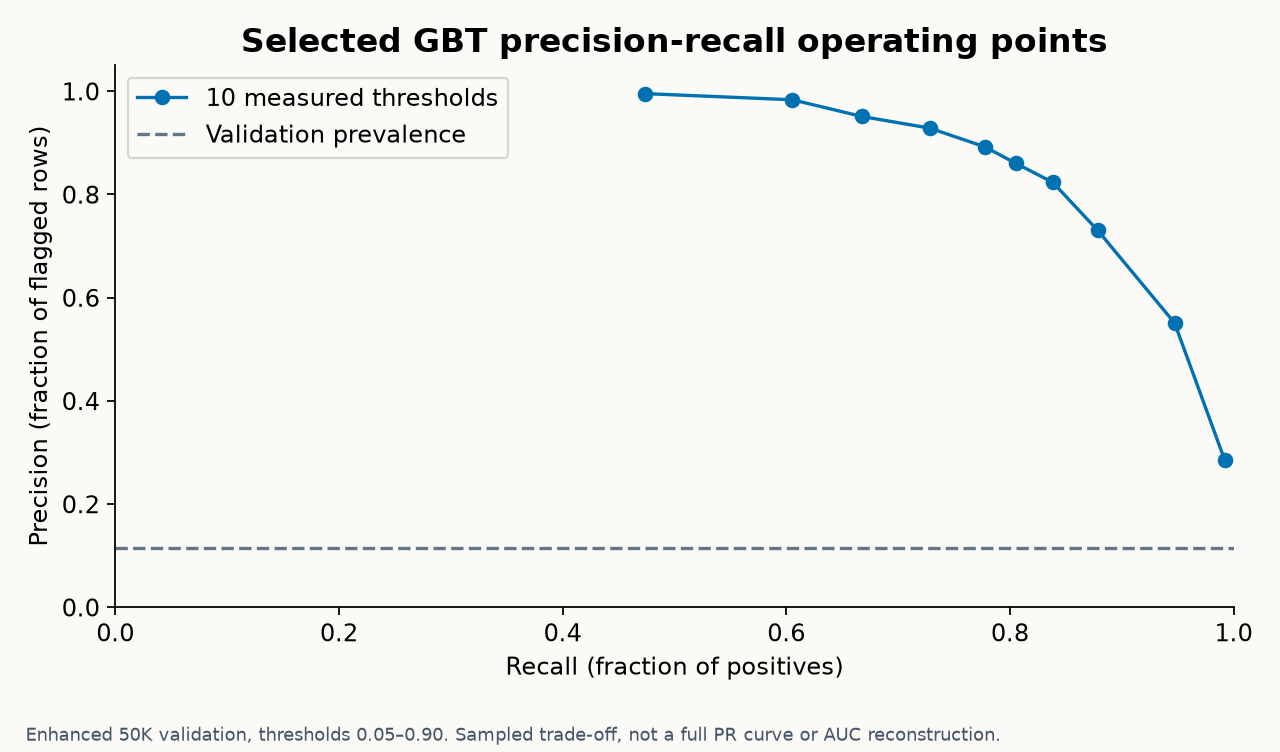

In [13]:
show_figure("precision_recall")

**Insight.** Higher-recall sampled thresholds reduce precision in validation.

**Operational implication.** Use threshold points to discuss workload trade-offs.

**Caution.** No saved score-level public predictions support a complete PR curve. Do not integrate these ten points as the reported Spark PR-AUC.


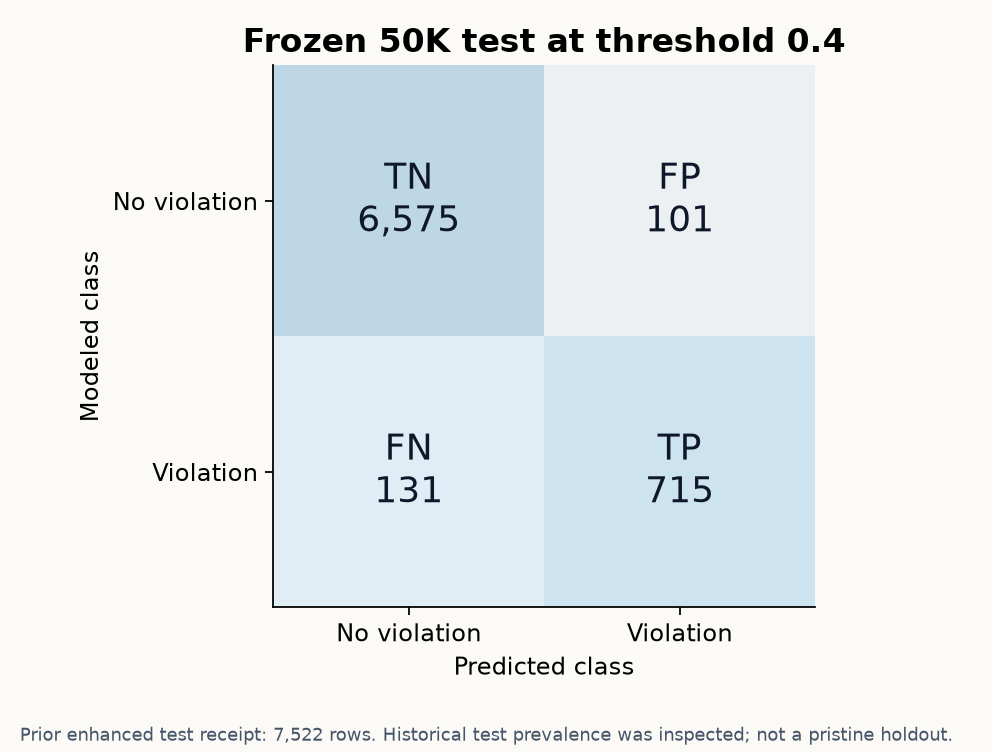

In [14]:
show_figure("confusion_matrix")

**Insight.** The selected test operating point misses 131 modeled positives and flags 101 negatives.

**Operational implication.** Engineering review must account for residual false negatives.

**Caution.** Previously evaluated test, with historical prevalence exposure. Not a fresh independent safety estimate.


### Screening budget (50K development)

#### Objective
What does review capacity buy beyond a single threshold?

#### Method
Globally sort validation by score descending. Break ties by scenario_id/outage_line_id. Choose ceil(N × budget). Compare loading on identical rows and budgets.

#### Evidence
At 20% nominal budget: GBT 830 positives, loading 693, each 1,531 rows. Difference 137 captured positives.

#### Insight
The learned ranking adds 15.71 percentage points of capture at the same row budget.

#### Decision or implication
Use budget curves to define a review-prioritization experiment.

#### Limitation
Pooled across scenarios, not a within-scenario dispatch screen. Deterministic tie handling may affect loading ties. No cost/time saving or zero-miss threshold is established.


In [15]:
show_table(screening_rows(ROOT), ["score","budget","number_screened","percent_screened","violations_captured","capture_rate","violations_missed","workload_reduction"])

| score | budget | number_screened | percent_screened | violations_captured | capture_rate | violations_missed | workload_reduction |
|---|---|---|---|---|---|---|---|
| risk_score | 0.01 | 77 | 1.0064 | 76 | 0.087156 | 796 | 0.989936 |
| risk_score | 0.05 | 383 | 5.00588 | 381 | 0.436927 | 491 | 0.949941 |
| risk_score | 0.1 | 766 | 10.0118 | 680 | 0.779817 | 192 | 0.899882 |
| risk_score | 0.2 | 1531 | 20.0105 | 830 | 0.951835 | 42 | 0.799895 |
| Pre_Outage_Line_Loading | 0.01 | 77 | 1.0064 | 74 | 0.0848624 | 798 | 0.989936 |
| Pre_Outage_Line_Loading | 0.05 | 383 | 5.00588 | 282 | 0.323394 | 590 | 0.949941 |
| Pre_Outage_Line_Loading | 0.1 | 766 | 10.0118 | 466 | 0.534404 | 406 | 0.899882 |
| Pre_Outage_Line_Loading | 0.2 | 1531 | 20.0105 | 693 | 0.794725 | 179 | 0.799895 |


The earlier 50K development study measured four review budgets. The fresh Dataproc export currently contains only 20%, so no lower fresh points are inferred. Pooled ranking does not allocate equal capacity to each operating state. The local audit also reports within-scenario metrics at 10% and 20%.


[Back to Top](#scrollTo=gridguard-cover)


<a id="fresh-dataproc"></a>
## 8. Fresh 1M Dataproc Results


**Objective.** Compare the fresh 1M run with the local 1M workflow on the declared sorted-ID split.

**Method.** This report renders recorded aggregates. The fresh Dataproc run, October 2026, used the canonical 1M input, nine predictors and scenario-grouped partitions. New code guards the input hash and validation population before local follow-up experiments.

**Evidence.** The split has 696,268 training rows, 153,105 validation rows and 150,627 test rows across 3,934, 865 and 851 scenarios. Recorded pairwise overlap is zero. Fresh runtime is Spark 4.1.2, Python 3.12.13 and Java 21.0.12.1. Local reproduction used Spark 4.0.1, Python 3.11.5 and recorded Java 21.0.1. Counts alone do not prove historical per-ID membership.

**Insight.** Local 1M is the appropriate reproduction comparison. Historical 1M used a different validation population. The fresh Dataproc RF PR-AUC falls within the range observed across 15 local seed-and-partition experiments. This is consistent with Random Forest stochastic variability, but the experiment does not isolate partition count as the unique cause. Fixed-threshold precision was not reproduced by the sensitivity study. The original local precision (0.941) and fresh Dataproc precision (0.878) both fall outside the 15-run local range of approximately 0.890 to 0.937. The sensitivity study used a different training-data layout from the original local reference run, so it characterizes nearby stochastic/layout variation rather than reproducing that reference run exactly.

**Decision or implication.** Keep model, split and operating policy fixed when comparing environments. Runtime differences alone do not demonstrate scaling speedup.

**Limitation.** Only two fresh thresholds and one budget are exported here. Additional points require the saved private manifest, not inferred values or another cloud run.


In [16]:
from gridguard.reporting import fresh_cloud, audit_fresh_cloud, fresh_figures
cloud = fresh_cloud(ROOT)
audit_fresh_cloud(ROOT)
fresh_figure_manifest = fresh_figures(ROOT)
show_table([dict(model=m, **r) for m, r in cloud["metrics"].items()])
show_table([dict(partition=k, **v) for k,v in cloud["evidence"]["split_summary"].items()])
show_table([dict(model=m, local_PR_AUC=load_json(ROOT,f"results/big/{m}/metrics.json")["PR_AUC"], fresh_PR_AUC=cloud["metrics"][m]["PR_AUC"]) for m in ["lr","rf","gbt"]])


| model | PR_AUC | ROC_AUC | precision | recall | F1 | TP | FP | FN | TN | threshold |
|---|---|---|---|---|---|---|---|---|---|---|
| lr | 0.8555 | 0.969983 | 0.831311 | 0.687581 | 0.752646 | 12197 | 2475 | 5542 | 132891 | 0.5 |
| rf | 0.868332 | 0.965658 | 0.878441 | 0.656689 | 0.751548 | 11649 | 1612 | 6090 | 133754 | 0.5 |
| gbt | 0.924999 | 0.982482 | 0.925978 | 0.782062 | 0.847957 | 13873 | 1109 | 3866 | 134257 | 0.5 |


| partition | rows | scenarios |
|---|---|---|
| train | 696268 | 3934 |
| validation | 153105 | 865 |
| test | 150627 | 851 |


| model | local_PR_AUC | fresh_PR_AUC |
|---|---|---|
| lr | 0.855497 | 0.8555 |
| rf | 0.876171 | 0.868332 |
| gbt | 0.924658 | 0.924999 |


**Insight.** The correct reproduction reference is the local 1M run on the declared sorted-ID split. Historical 1M used a different validation population. Local RF PR-AUC 0.87617 differs from fresh 0.86833. The 15-run seed-and-partition study spans the fresh RF PR-AUC, without identifying a unique cause.

**Operational implication.** Keep the discrepancy visible and preserve model-specific evidence rather than declaring every metric replicated exactly.

**Caution.** Effective fresh parameter maps and per-scenario historical membership are unavailable locally. Runtime, implementation and population differences are candidate explanations, not isolated causes. See [RF discrepancy audit](../docs/RF_REPRODUCIBILITY_AUDIT.md).


| budget | score | number_screened | percent_screened | violations_captured | capture_rate | violations_missed | workload_reduction |
|---|---|---|---|---|---|---|---|
| 0.2 | risk_score | 30621 | 20 | 16812 | 0.947742 | 927 | 0.8 |
| 0.2 | Pre_Outage_Line_Loading | 30621 | 20 | 13974 | 0.787756 | 3765 | 0.8 |


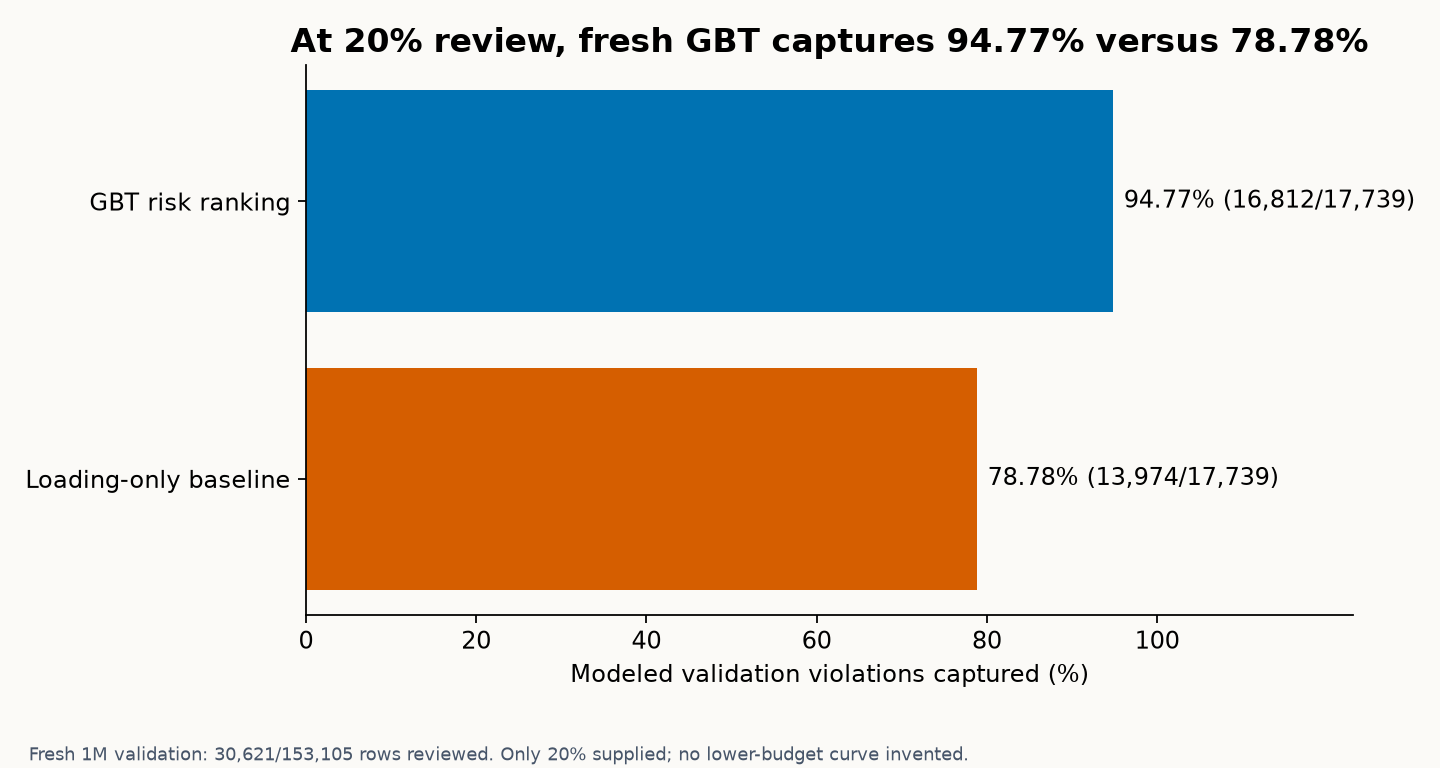

In [17]:
show_table(cloud["screening"])
show_figure("dataproc_screening_20pct")


**Insight.** Reviewing 30,621 of 153,105 validation cases retains 16,812/17,739 modeled positives (94.77%) with GBT, versus 13,974/17,739 (78.78%) using loading alone. GBT still misses 927 positives.

**Operational implication.** This observed budget leaves 80% of cases outside detailed review while retaining the stated fraction of modeled violations. It measures candidate workload, not labor savings or operational safety.

**Caution.** Only one budget was supplied. No fresh lower-budget curve, scenario guarantee, external-grid transfer or calibrated risk probability is established.


| threshold | precision | recall | F1 | percent_flagged | workload_reduction |
|---|---|---|---|---|---|
| 0.4 | 0.886177 | 0.820734 | 0.852201 | 10.7305 | 0.892695 |
| 0.5 | 0.925978 | 0.782062 | 0.847957 | 9.7854 | 0.902146 |


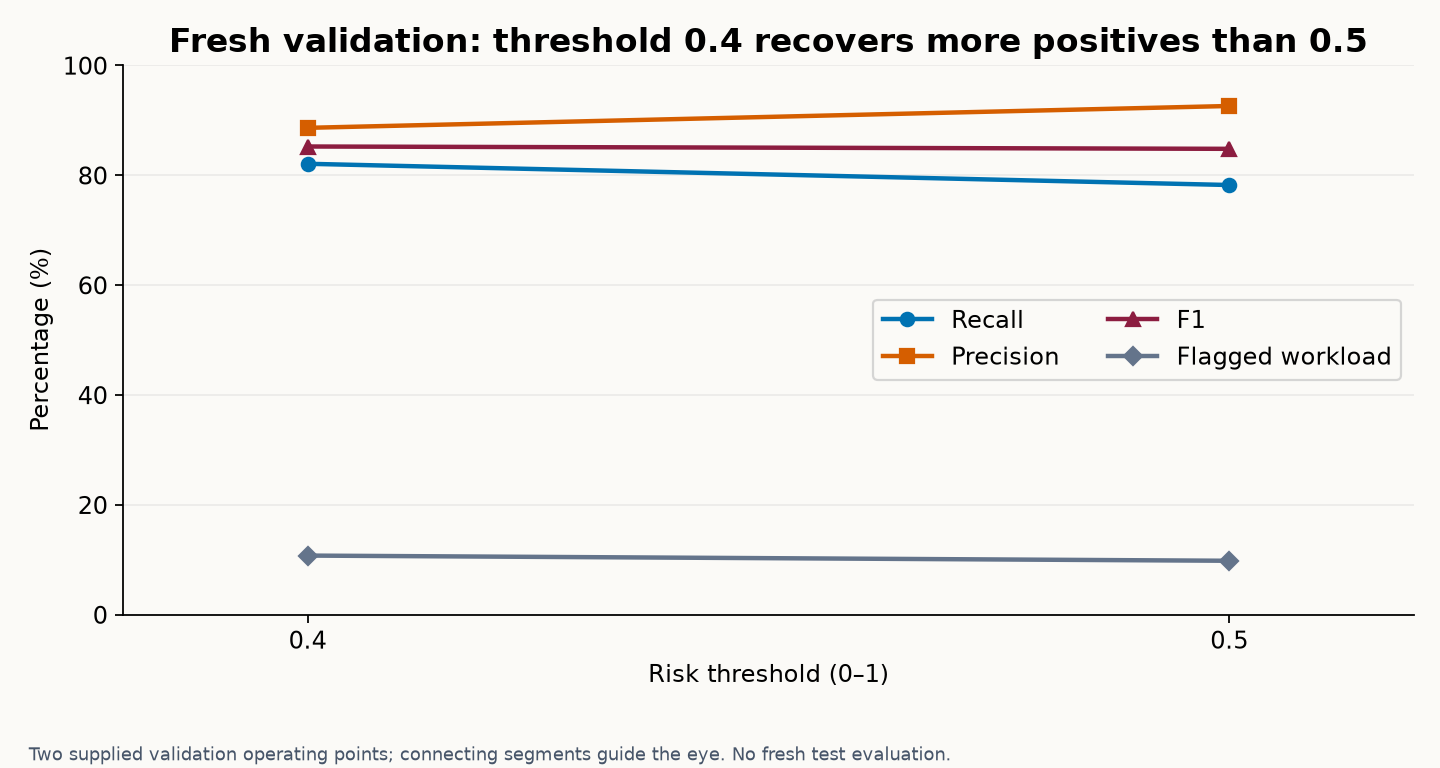

In [18]:
show_table(cloud["thresholds"])
show_figure("dataproc_threshold_tradeoff")


**Insight.** At threshold 0.4, validation recall is 0.82073 compared with 0.78206 at 0.5, with lower precision and more flagged cases.

**Decision or implication.** Treat these as two recorded validation operating points. A final recall-target or budget rule needs written approval before any test assessment.

**Limitation.** The fresh 150,627-row test remains unevaluated. These points do not establish a new frozen policy.


[Back to Top](#scrollTo=gridguard-cover)


<a id="batch-scoring"></a>
## 9. Operational Interpretation and Batch Scoring


Target-free batch scoring validates numeric predictors, loads a saved Spark pipeline and writes a score, rank, class, model-content version, threshold, input checksum and timestamp. Private row-level outputs are not part of the public report.

Scoring mechanics have been checked on synthetic fixtures. Canonical replay evidence remains a separate requirement. A failed screen must not justify studying fewer cases. A real engineering workflow would fall back to full analysis and human review. Production monitoring and access controls remain proposed.


[Back to Top](#scrollTo=gridguard-cover)


<a id="limitations"></a>
## 10. Limitations


The conclusions are bounded by synthetic DC thermal labels, a fixed benchmark topology and a missing original generator. These data do not establish AC security, stability, calibrated failure probability or transfer to utility operations. Exact sensitivity construction remains uncertain.

Published pooled validation metrics also reflect model and operating-point selection on validation. The earlier assessed 50K test had historical prevalence exposure. The fresh 1M test is reserved. Independent-topology validation, subgroup performance and calibration remain open. Capture and scenario-recall intervals are reported for the local validation audit.


## Evaluation limits

The 50K and 1M datasets share the same 5,650 operating scenarios. The 1M dataset adds denser outage coverage rather than independent operating states. Ratings were reportedly calibrated on 5,000 scenarios. Their overlap with modeled scenarios is unknown, so calibration may carry information from validation or test flows. Existing published review rankings pool cases across scenarios and do not enforce equal review capacity within each state. The completed local audit reports heuristic and within-scenario comparisons.


[Back to Top](#scrollTo=gridguard-cover)


<a id="reproducibility"></a>
## 11. Reproducibility


Report reproduction uses the saved sanitized aggregate JSON, shared plotting code and bibliography. It requires the repository and declared report dependencies but no canonical data. The standalone notebook can be viewed with its saved outputs without executing its code. Executing repository-dependent cells in an isolated Colab upload is not a supported clean-run workflow.

ML reproduction needs authorized external inputs. New review experiments use new results/local directories and never replace frozen measurements. [Reproduction instructions](../docs/REPRODUCIBILITY.md) distinguish those workflows. Docker and CI definitions are prepared but no container or hosted CI success is claimed.


In [19]:
# Optional read-only private-data audit. Default mode needs no canonical data.
# Enable only with authorized external inputs; never display resolved paths or records.
if os.environ.get("GRIDGUARD_REPORT_VALIDATE_PRIVATE") == "1":
    from gridguard.config import load
    from gridguard.reporting import integrity_profile
    authorized = load(ROOT / "configs/development.yaml")
    audit = integrity_profile(authorized["data"])
    show_table([{k:audit[k] for k in ["rows","column_count","missing_cells","duplicate_scenario_outage_pairs","prevalence"]}])
else:
    print("Private-data validation skipped by explicit default. Preserved aggregate profile displayed above.")

Private-data validation skipped by explicit default. Preserved aggregate profile displayed above.


[Back to Top](#scrollTo=gridguard-cover)


<a id="conclusions"></a>
## 12. Conclusion


On the local 1M validation split, GBT increased modeled-violation capture at a 20% review budget from 78.78% for the strongest tested simple baseline to 95.07%, a gain of 16.29 percentage points. Across 1,000 paired scenario-cluster bootstrap resamples, the 95% interval for the gain was +15.75 to +16.72 points.

Mean per-scenario recall at 20% increased from 79.39% to 93.80%, a +14.41-point gain with interval +13.85 to +14.97. Pooled capture and within-scenario recall describe different review policies. Intervals do not correct selection optimism or calibration overlap.

The budget policy is frozen in the written policy record. The held-out 1M test remains unevaluated, and scoring requires separate authorization. Fresh Dataproc results remain a separate evidence layer. The synthetic DC benchmark does not establish utility performance. Calibration overlap is unknown and the original generator is missing, so full canonical regeneration remains unsupported.


[Back to Top](#scrollTo=gridguard-cover)


<a id="references"></a>
## 13. References and Appendices


APA 7 author-date references generated from references.bib. Official undated documentation uses n.d. With disambiguating letters. Documentation accessed October 16, 2026. The literature matrix records exact verified links and exceptions.

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. [https://doi.org/10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324)

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. [https://doi.org/10.1214/aos/1013203451](https://doi.org/10.1214/aos/1013203451)

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé, H., III, & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92. [https://doi.org/10.1145/3458723](https://doi.org/10.1145/3458723)

Hidalgo-Arteaga, J.-M., Hancharou, F., Thams, F., & Chatzivasileiadis, S. (2019). Deep learning for power system security assessment. In *2019 IEEE Milan PowerTech* (pp. 1–6). IEEE. [https://doi.org/10.1109/PTC.2019.8810906](https://doi.org/10.1109/PTC.2019.8810906)

Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15. [https://doi.org/10.1145/2382577.2382579](https://doi.org/10.1145/2382577.2382579)

MATPOWER Developers (n.d.-a). case118: Power flow data for IEEE 118 bus test case. MATPOWER 6.0 function reference. [https://matpower.org/docs/ref/matpower 6.0/case118.html](https://matpower.org/docs/ref/matpower6.0/case118.html)

MATPOWER Developers (n.d.-b). makeLODF. *MATPOWER 8.1 documentation*. [https://matpower.org/documentation/ref-manual/legacy/functions/makeLODF.html](https://matpower.org/documentation/ref-manual/legacy/functions/makeLODF.html)

Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D., & Gebru, T. (2019). Model cards for model reporting. In *Proceedings of the Conference on Fairness, Accountability, and Transparency* (pp. 220–229). Association for Computing Machinery. [https://doi.org/10.1145/3287560.3287596](https://doi.org/10.1145/3287560.3287596)

North American Electric Reliability Corporation (n.d.). TPL-001-5.1: Transmission system planning performance requirements. *Reliability standard*. [https://www.nerc.com/globalassets/standards/reliability-standards/tpl/tpl-001-5.1.pdf](https://www.nerc.com/globalassets/standards/reliability-standards/tpl/tpl-001-5.1.pdf)

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. [https://doi.org/10.1111/ecog.02881](https://doi.org/10.1111/ecog.02881)

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLOS ONE, 10(3), Article e0118432. [https://doi.org/10.1371/journal.pone.0118432](https://doi.org/10.1371/journal.pone.0118432)

Thams, F., Venzke, A., Eriksson, R., & Chatzivasileiadis, S. (2020). Efficient database generation for data-driven security assessment of power systems. *IEEE Transactions on Power Systems, 35*(1), 30–41. [https://doi.org/10.1109/TPWRS.2018.2890769](https://doi.org/10.1109/TPWRS.2018.2890769)

The Apache Software Foundation (n.d.-a). ML pipelines. *Apache Spark 3.5.8 documentation*. [https://spark.apache.org/docs/3.5.8/ml-pipeline.html](https://spark.apache.org/docs/3.5.8/ml-pipeline.html)

The Apache Software Foundation (n.d.-b). pyspark.sql.DataFrame.toPandas. *PySpark 3.5.8 documentation*. [https://spark.apache.org/docs/3.5.8/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.toPandas.html](https://spark.apache.org/docs/3.5.8/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.toPandas.html)

Zaharia, M., Chowdhury, M., Das, T., Dave, A., Ma, J., McCauley, M., Franklin, M. J., Shenker, S., & Stoica, I. (2012). Resilient distributed datasets: A fault-tolerant abstraction for in-memory cluster computing. 9th USENIX Symposium on Networked Systems Design and Implementation (NSDI 12), pp. 15–28. [https://www.usenix.org/conference/nsdi12/technical-sessions/presentation/zaharia](https://www.usenix.org/conference/nsdi12/technical-sessions/presentation/zaharia)

Zimmerman, R. D., Murillo-Sánchez, C. E., & Thomas, R. J. (2011). MATPOWER: Steady-state operations, planning, and analysis tools for power systems research and education. *IEEE Transactions on Power Systems, 26*(1), 12–19. [https://doi.org/10.1109/TPWRS.2010.2051168](https://doi.org/10.1109/TPWRS.2010.2051168)


- [Appendix A: Data Dictionary](#appendix-a)
- [Appendix B: Data Integrity Audit](#appendix-b)
- [Appendix C: Split and Leakage Audit](#appendix-c)
- [Appendix D: Model Hyperparameters](#appendix-d)
- [Appendix E: Complete Evaluation Tables](#appendix-e)
- [Appendix F: Threshold and Screening Tables](#appendix-f)
- [Appendix G: Reproducibility Environment](#appendix-g)
- [Appendix H: Data Access and Privacy](#appendix-h)
- [Appendix I: Evidence State Register](#appendix-i)
- [Appendix J: Limitations and Open Work](#appendix-j)


<a id="appendix-a"></a>
### Appendix A: Data Dictionary


| Field | Interpretation |
|---|---|
| `Total_Demand` | Total scenario demand (MW) |
| `Renewable_Generation_Pct` | Scenario renewable generation percentage |
| `Hour_of_Day` | Operating hour (0–23) |
| `Pre_Outage_Line_Loading` | Candidate line loading before outage. Benchmark percentage feature |
| `Line_Thermal_Rating` | Synthetic calibrated line rating (MW), not utility equipment rating |
| `Edge_Betweenness` | Network edge betweenness feature. Exact normalization awaits generator source |
| `Degree_From_Bus` | From-bus graph degree |
| `Degree_To_Bus` | To-bus graph degree |
| `Line_Outage_Sensitivity` | LODF-derived sensitivity summary. Exact construction awaits generator source |
| `Post_Outage_Violation` | Binary modeled thermal violation after outage |
| `scenario_id` | Operating scenario identifier. Grouping only |
| `outage_line_id` | Candidate outage identifier. Traceability only |
| `random_seed` | Generation metadata. Excluded from predictors |
| `dataset_version` | CSV version string. Excluded from predictors |
| `islanding_flag` | Retained-population metadata. All canonical values zero |

Nine predictors are numeric. Metadata includes IDs/seed/flag and a version string. Target is binary. Exact sensitivity/centrality construction awaits the generator.


<a id="appendix-b"></a>
### Appendix B: Data Integrity Audit


In [20]:
show_table([{k:profile[k] for k in ["rows","column_count","missing_cells","duplicate_scenario_outage_pairs","target_validity","unique_scenarios","versions","sha256"]}])

| rows | column_count | missing_cells | duplicate_scenario_outage_pairs | target_validity | unique_scenarios | versions | sha256 |
|---|---|---|---|---|---|---|---|
| 50000 | 15 | 0 | 0 | binary 0/1 | 5650 | ['ieee118_dc_lodf_v1'] | 0647a744810f26691d2f46ee176a2d167c1beb1ce88a076be69a69b445226ec9 |


<a id="appendix-c"></a>
### Appendix C: Split and Leakage Audit


Actual partitions: [split summary](../results/small/split_summary.json). Source asserts pairwise disjoint scenario joins. Three training-only folds hash scenario_id plus seed. Historical per-ID manifests unavailable. See [expert review](../docs/METHODS.md).


<a id="appendix-d"></a>
### Appendix D: Model Hyperparameters


In [21]:
show_table([dict(model=n, parameters=load_json(ROOT,f"results/small/{n}/parameters.json")) for n in ["lr","rf","gbt"]])
show_table(tuning["records"])

| model | parameters |
|---|---|
| lr | {'aggregationDepth': 2, 'elasticNetParam': 0.0, 'family': 'auto', 'featuresCol': 'features', 'fitIntercept': True, 'labelCol': 'Post_Outage_Violation', 'maxBlockSizeInMB': 0.0, 'maxIter': 100, 'predictionCol': 'prediction', 'probabilityCol': 'probability', 'rawPredictionCol': 'rawPrediction', 'regParam': 0.0, 'standardization': True, 'threshold': 0.5, 'tol': 1e-06} |
| rf | {'bootstrap': True, 'cacheNodeIds': False, 'checkpointInterval': 10, 'featureSubsetStrategy': 'auto', 'featuresCol': 'features', 'impurity': 'gini', 'labelCol': 'Post_Outage_Violation', 'leafCol': '', 'maxBins': 32, 'maxDepth': 5, 'maxMemoryInMB': 256, 'minInfoGain': 0.0, 'minInstancesPerNode': 1, 'minWeightFractionPerNode': 0.0, 'numTrees': 20, 'predictionCol': 'prediction', 'probabilityCol': 'probability', 'rawPredictionCol': 'rawPrediction', 'seed': 4152026, 'subsamplingRate': 1.0} |
| gbt | {'cacheNodeIds': False, 'checkpointInterval': 10, 'featureSubsetStrategy': 'all', 'featuresCol': 'features', 'impurity': 'variance', 'labelCol': 'Post_Outage_Violation', 'leafCol': '', 'lossType': 'logistic', 'maxBins': 32, 'maxDepth': 5, 'maxIter': 20, 'maxMemoryInMB': 256, 'minInfoGain': 0.0, 'minInstancesPerNode': 1, 'minWeightFractionPerNode': 0.0, 'predictionCol': 'prediction', 'probabilityCol': 'probability', 'rawPredictionCol': 'rawPrediction', 'seed': 4152026, 'stepSize': 0.1, 'subsamplingRate': 1.0, 'validationTol': 0.01} |


| parameters | fold_scores | mean_PR_AUC |
|---|---|---|
| {'maxDepth': 3, 'maxIter': 20} | [0.863576590036629, 0.8669378755519529, 0.8753096277994494] | 0.868608 |
| {'maxDepth': 5, 'maxIter': 20} | [0.9083748432407278, 0.9193545928327101, 0.9176534911698772] | 0.915128 |


<a id="appendix-e"></a>
### Appendix E: Complete Evaluation Tables


In [22]:
show_table(metric_rows(ROOT))
show_table([dict(view=k, **v) for k,v in load_json(ROOT,"results/small/final_test.json").items() if k in ["ranking","operating"]])

| dataset | model | evidence | TP | FP | FN | TN | precision | recall | F1 | threshold | percent_flagged | workload_reduction | PR_AUC | ROC_AUC |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| small | lr | REPRODUCED | 600 | 127 | 272 | 6652 | 0.825309 | 0.688073 | 0.750469 | 0.5 | 9.50203 | 0.90498 | 0.847667 | 0.969637 |
| small | rf | REPRODUCED | 540 | 56 | 332 | 6723 | 0.90604 | 0.619266 | 0.735695 | 0.5 | 7.78983 | 0.922102 | 0.858816 | 0.962958 |
| small | gbt | REPRODUCED | 678 | 82 | 194 | 6697 | 0.892105 | 0.777523 | 0.830882 | 0.5 | 9.93334 | 0.900667 | 0.914165 | 0.981003 |
| big | lr | REPRODUCED | 12197 | 2475 | 5542 | 132891 | 0.831311 | 0.687581 | 0.752646 | 0.5 | 9.58297 | 0.90417 | 0.855497 | 0.969983 |
| big | rf | REPRODUCED | 10989 | 687 | 6750 | 134679 | 0.941161 | 0.619482 | 0.74717 | 0.5 | 7.62614 | 0.923739 | 0.876171 | 0.964734 |
| big | gbt | REPRODUCED | 13894 | 1239 | 3845 | 134127 | 0.918126 | 0.783246 | 0.845339 | 0.5 | 9.88407 | 0.901159 | 0.924658 | 0.982737 |


| view | TP | FP | FN | TN | precision | recall | F1 | threshold | percent_flagged | workload_reduction | PR_AUC | ROC_AUC |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ranking | 692 | 65 | 154 | 6611 | 0.914135 | 0.817967 | 0.863381 | 0.5 | 10.0638 | 0.899362 | 0.931811 | 0.98475 |
| operating | 715 | 101 | 131 | 6575 | 0.876225 | 0.845154 | 0.860409 | 0.4 | 10.8482 | 0.891518 |  |  |


<a id="appendix-f"></a>
### Appendix F: Threshold and Screening Tables


In [23]:
show_table(load_json(ROOT,"results/small/thresholds_selected.json"))
show_table(screening_rows(ROOT))

| TP | FP | FN | TN | precision | recall | F1 | threshold | percent_flagged | workload_reduction |
|---|---|---|---|---|---|---|---|---|---|
| 865 | 2165 | 7 | 4614 | 0.285479 | 0.991972 | 0.443362 | 0.05 | 39.6027 | 0.603973 |
| 826 | 674 | 46 | 6105 | 0.550667 | 0.947248 | 0.696459 | 0.1 | 19.6053 | 0.803947 |
| 766 | 283 | 106 | 6496 | 0.730219 | 0.87844 | 0.797501 | 0.2 | 13.7106 | 0.862894 |
| 731 | 157 | 141 | 6622 | 0.823198 | 0.838303 | 0.830682 | 0.3 | 11.6063 | 0.883937 |
| 702 | 114 | 170 | 6665 | 0.860294 | 0.805046 | 0.831754 | 0.4 | 10.6653 | 0.893347 |
| 678 | 82 | 194 | 6697 | 0.892105 | 0.777523 | 0.830882 | 0.5 | 9.93334 | 0.900667 |
| 635 | 49 | 237 | 6730 | 0.928363 | 0.728211 | 0.816195 | 0.6 | 8.94001 | 0.9106 |
| 582 | 30 | 290 | 6749 | 0.95098 | 0.667431 | 0.784367 | 0.7 | 7.99895 | 0.92001 |
| 528 | 9 | 344 | 6770 | 0.98324 | 0.605505 | 0.749468 | 0.8 | 7.01869 | 0.929813 |
| 413 | 2 | 459 | 6777 | 0.995181 | 0.473624 | 0.641803 | 0.9 | 5.42413 | 0.945759 |


| budget | score | number_screened | percent_screened | violations_captured | capture_rate | violations_missed | workload_reduction | prevalence | best_possible | share_of_best | best_possible_realized | share_of_best_realized |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.01 | risk_score | 77 | 1.0064 | 76 | 0.087156 | 796 | 0.989936 | 0.113972 | 0.0877408 | 0.993334 | 0.0883028 | 0.987013 |
| 0.05 | risk_score | 383 | 5.00588 | 381 | 0.436927 | 491 | 0.949941 | 0.113972 | 0.438704 | 0.995948 | 0.43922 | 0.994778 |
| 0.1 | risk_score | 766 | 10.0118 | 680 | 0.779817 | 192 | 0.899882 | 0.113972 | 0.877408 | 0.888773 | 0.87844 | 0.887728 |
| 0.2 | risk_score | 1531 | 20.0105 | 830 | 0.951835 | 42 | 0.799895 | 0.113972 | 1 | 0.951835 | 1 | 0.951835 |
| 0.01 | Pre_Outage_Line_Loading | 77 | 1.0064 | 74 | 0.0848624 | 798 | 0.989936 | 0.113972 | 0.0877408 | 0.967194 | 0.0883028 | 0.961039 |
| 0.05 | Pre_Outage_Line_Loading | 383 | 5.00588 | 282 | 0.323394 | 590 | 0.949941 | 0.113972 | 0.438704 | 0.737159 | 0.43922 | 0.736292 |
| 0.1 | Pre_Outage_Line_Loading | 766 | 10.0118 | 466 | 0.534404 | 406 | 0.899882 | 0.113972 | 0.877408 | 0.609071 | 0.87844 | 0.608355 |
| 0.2 | Pre_Outage_Line_Loading | 1531 | 20.0105 | 693 | 0.794725 | 179 | 0.799895 | 0.113972 | 1 | 0.794725 | 1 | 0.794725 |


<a id="appendix-g"></a>
### Appendix G: Reproducibility Environment

Local reproduction recorded Spark 4.0.1, Python 3.11.5 and Java 21.0.1. Fresh Dataproc run, October 2026, recorded Spark 4.1.2, Python 3.12.13 and Java 21.0.12.1. The table labels these separate environments and the report-rendering dependencies. Rendering this report does not fit Spark models.


In [24]:
show_table([dict(evidence_layer="50K development" if s=="small" else "1M local reproduction", **load_json(ROOT,f"results/{s}/manifest.json")["environment"]) for s in ["small","big"]])
show_table([dict(evidence_layer="Fresh 1M manual Dataproc reproduction", **cloud["evidence"]["environment"])])
from importlib.metadata import version
show_table([{"report_component":name,"version":version(name)} for name in ["nbformat","nbclient","nbconvert","ipykernel","matplotlib","pyspark","PyYAML"]])
print("Recorded local ML Java: 21.0.1; user-verified Dataproc Java: 21.0.12.1. No Java runtime is invoked by this aggregate report.")


| evidence_layer | python | platform | pyspark |
|---|---|---|---|
| 50K development | 3.11.5 | macOS-26.7.1-x86_64-i386-64bit | 4.0.1 |
| 1M local reproduction | 3.11.5 | macOS-26.7.1-x86_64-i386-64bit | 4.0.1 |


| evidence_layer | spark | python | java | spark.master | spark.submit.deployMode | spark.driver.memory | spark.driver.maxResultSize | spark.executor.memory | spark.executor.memoryOverhead | spark.executor.cores | spark.executor.instances | spark.dynamicAllocation.enabled | spark.sql.shuffle.partitions |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Fresh 1M manual Dataproc reproduction | 4.1.2 | 3.12.13 | 21.0.12.1 | yarn | client | 4g | 128m | 3g | 1g | 2 | 2 | False | 8 |


| report_component | version |
|---|---|
| nbformat | 5.11.1 |
| nbclient | 0.11.0 |
| nbconvert | 7.17.2 |
| ipykernel | 7.4.0 |
| matplotlib | 3.11.2 |
| pyspark | 4.0.1 |
| PyYAML | 6.0.3 |


Recorded local ML Java: 21.0.1; user-verified Dataproc Java: 21.0.12.1. No Java runtime is invoked by this aggregate report.


<a id="appendix-h"></a>
### Appendix H: Data Access and Privacy


Canonical data are private, outside this tree, and never uploaded to GridRail. Set GRIDGUARD_DATA_DIR or per-file variables. No `.env` values, record-level samples, model binaries, raw logs or private mapping are included. See [policy](../docs/PRIVATE_DATA_ACCESS.md).


<a id="appendix-i"></a>
### Appendix I: Evidence State Register


| Evidence layer | Scope | Boundary |
|---|---|---|
| 50K development | Earlier development and exposed test experiment | Not current confirmatory evidence |
| Historical 1M course evidence | Original reported results with a different validation population | Context rather than direct reproduction target |
| Local 1M validation/reproduction | Recorded local Spark LR, RF and GBT run | Validation only |
| Fresh 1M Dataproc validation/reproduction | Fresh cloud run, October 2026 | Separate runtime evidence, only measured fresh budgets |
| Local 1M validation audit, October 2026 | Same local 1M split and GBT model. Stronger baseline, per-scenario metrics, ceilings, RF study and paired bootstrap | Validation only. Selection optimism remains. Test unused |


<a id="appendix-j"></a>
### Appendix J: Limitations and Open Work


### Completed

The local audit includes stronger baselines, per-scenario metrics, EDA, screening ceilings, 15 RF runs and 1,000 paired scenario-bootstrap draws. Fresh Dataproc results remain separate. The written budget policy freezes the model, baseline, features and evaluation rules.

### Open work

Fresh-clone execution and container/hosted CI remain unverified. Manual Colab replacement is required after this rebuild. Audit pruning requires approval. A future held-out test run requires separate written authorization. Dataset redistribution rights remain unestablished and private CSVs remain excluded. Generator recovery and external utility validity remain research limits.


### Outage density: 9 versus 177 outages per scenario

Both datasets use the same 5,650 scenarios. The 50K and 1M comparison measures denser candidate coverage, not controlled scaling speedup or independent-population growth. See [Results](../docs/RESULTS.md).


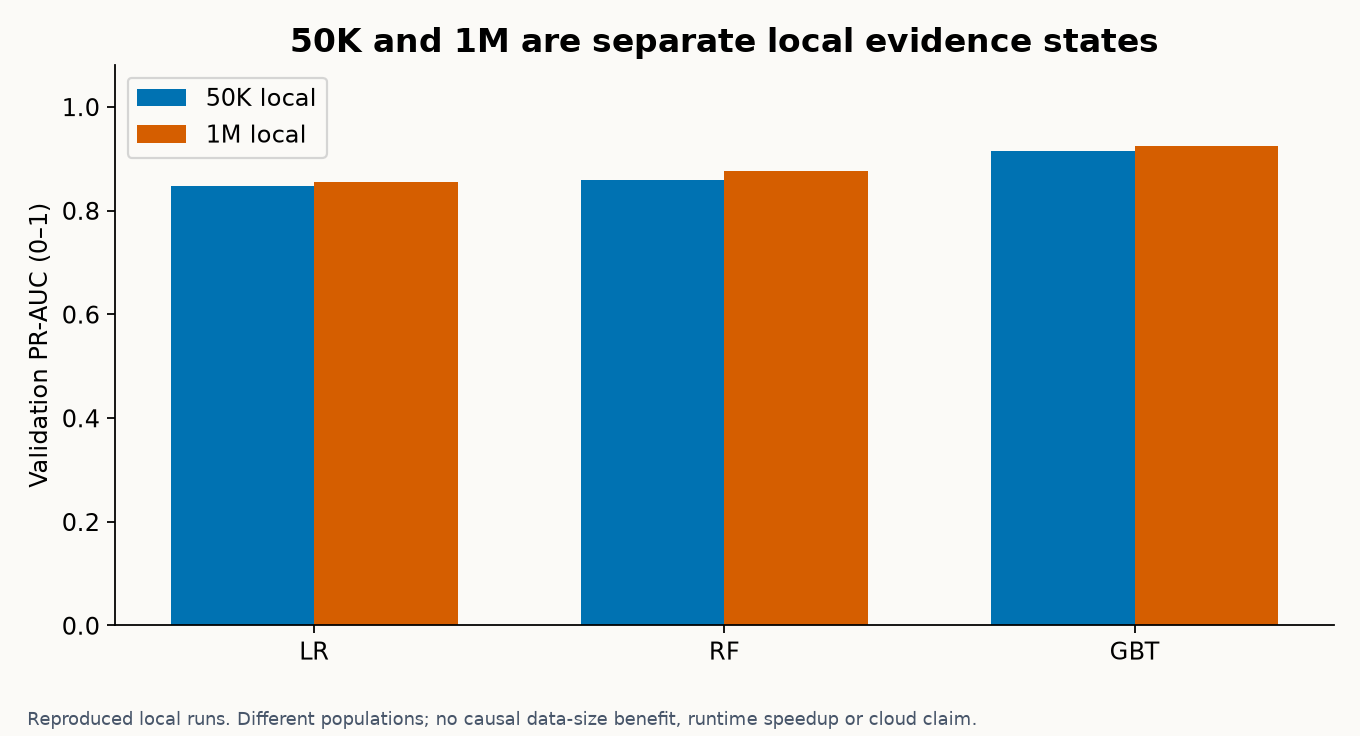

In [25]:
show_figure("scaling_results")

[Back to Top](#scrollTo=gridguard-cover)
